# Étape 4 : Extraction des caractéristiques
Objectif : transformer chaque image en un vecteur de nombres exploitable par les algorithmes de machine learning.
- **Caractéristiques de couleur** : statistiques et histogrammes de chaque canal, dans chaque espace de couleur, calculés sur la fève seule.
- **Caractéristiques de texture** : GLCM, LBP, Gabor et HOG.
Toutes les matrices sont enregistrées dans `results/features/` pour l'étape 5.

In [1]:
#Chagement 

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage as ndi
from scipy.stats import skew, kurtosis

donnees = np.load("../data/donnees_feves.npz")
X, y = donnees["X"], donnees["y"]
masques = np.load("../data/masques_feves.npy").astype(bool)
df = pd.read_csv("../results/tables/02_decoupage.csv")

os.makedirs("../results/features", exist_ok=True)
print(X.shape, masques.shape, len(df))

(4470, 60, 60, 3) (4470, 60, 60) 4470


In [2]:
#Les fonctions

ESPACES = {"RGB": None, "HSV": cv2.COLOR_RGB2HSV, "LAB": cv2.COLOR_RGB2LAB,
           "YCbCr": cv2.COLOR_RGB2YCrCb, "HLS": cv2.COLOR_RGB2HLS}
NOMS_CANAUX = {"RGB": ["R", "G", "B"], "HSV": ["H", "S", "V"], "LAB": ["L", "a", "b"],
               "YCbCr": ["Y", "Cr", "Cb"], "HLS": ["H", "L", "S"]}

def convertir(img, espace):
    """Conversion de l'image + correction de la teinte (étape 3)."""
    z = img.copy() if ESPACES[espace] is None else cv2.cvtColor(img, ESPACES[espace])
    z = z.astype(np.int16)
    if espace in ["HSV", "HLS"]:
        z[..., 0] = (z[..., 0] + 90) % 180
    return z

def caracteristiques_couleur(img, masque, espace, nb_cases=8):
    """15 mesures par canal, calculées sur les pixels de la fève."""
    # On rogne le masque d'un pixel pour retirer le liseré bleuté
    masque_net = ndi.binary_erosion(masque, iterations=1)
    if masque_net.sum() < 50:              # sécurité si la fève est minuscule
        masque_net = masque

    img_conv = convertir(img, espace)
    resultat = {}
    for k, canal in enumerate(NOMS_CANAUX[espace]):
        p = img_conv[..., k][masque_net].astype(np.float64)
        prefixe = f"{espace}_{canal}"
        resultat[f"{prefixe}_moyenne"] = p.mean()
        resultat[f"{prefixe}_variance"] = p.var()
        resultat[f"{prefixe}_ecart_type"] = p.std()
        resultat[f"{prefixe}_min"] = p.min()
        resultat[f"{prefixe}_max"] = p.max()
        resultat[f"{prefixe}_asymetrie"] = skew(p)
        resultat[f"{prefixe}_aplatissement"] = kurtosis(p)

        borne = 180 if (espace in ["HSV", "HLS"] and k == 0) else 256
        hist, _ = np.histogram(p, bins=nb_cases, range=(0, borne))
        hist = hist / hist.sum()           # proportion de pixels dans chaque case
        for i in range(nb_cases):
            resultat[f"{prefixe}_hist{i}"] = hist[i]
    return resultat

In [3]:
#test sur une seule image, pour comprendre

exemple = caracteristiques_couleur(X[0], masques[0], "LAB")
print("Nombre de caractéristiques pour un espace :", len(exemple))
pd.Series(exemple).round(3).head(15)

Nombre de caractéristiques pour un espace : 45


LAB_L_moyenne          103.636
LAB_L_variance         378.562
LAB_L_ecart_type        19.457
LAB_L_min               54.000
LAB_L_max              184.000
LAB_L_asymetrie          0.764
LAB_L_aplatissement      0.392
LAB_L_hist0              0.000
LAB_L_hist1              0.009
LAB_L_hist2              0.391
LAB_L_hist3              0.460
LAB_L_hist4              0.132
LAB_L_hist5              0.010
LAB_L_hist6              0.000
LAB_L_hist7              0.000
dtype: float64

In [4]:
#calcul pour toutes les images et tous les espaces

lignes = []
for i in range(len(X)):
    ligne = {}
    for espace in ESPACES:
        ligne.update(caracteristiques_couleur(X[i], masques[i], espace))
    lignes.append(ligne)
    if (i + 1) % 1000 == 0:
        print(f"{i + 1} / {len(X)} images traitées")

df_couleur = pd.DataFrame(lignes)
print("\nMatrice des caractéristiques de couleur :", df_couleur.shape)
print("Valeurs manquantes :", df_couleur.isna().sum().sum())

# Sauvegarde, avec le nom du fichier et la classe pour garder le lien avec les images
df_couleur.insert(0, "fichier", df["fichier"])
df_couleur.insert(1, "classe", df["classe"])
df_couleur.to_csv("../results/features/caracteristiques_couleur.csv.gz", index=False)

1000 / 4470 images traitées
2000 / 4470 images traitées
3000 / 4470 images traitées
4000 / 4470 images traitées

Matrice des caractéristiques de couleur : (4470, 225)
Valeurs manquantes : 0


## Caractéristiques de texture
Calculées sur l'image en niveaux de gris :
- **GLCM** (matrice de co-occurrence) : contraste, homogénéité, énergie et corrélation, pour des distances de 1 et 2 pixels, moyennées sur 4 directions (0°, 45°, 90°, 135°).
- **LBP** (motifs binaires locaux) : histogramme des 10 motifs uniformes (8 voisins, rayon 1).
- **Gabor** : moyenne et écart-type de la réponse de 12 filtres (3 fréquences × 4 orientations).
- **HOG** (histogrammes de gradients orientés) : 9 orientations, cellules de 15 × 15 pixels, blocs de 2 × 2 cellules.

In [ ]:
#Les fonctions de texture

from skimage.feature import graycomatrix, graycoprops, local_binary_pattern, hog
from skimage.filters import gabor_kernel

gris = np.array([cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in X])
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

def texture_glcm(g):
    # On réduit à 32 niveaux de gris (au lieu de 256) : matrice plus stable et calcul plus rapide
    glcm = graycomatrix(g // 8, distances=[1, 2], angles=ANGLES, levels=32, symmetric=True, normed=True)
    resultat = {}
    for propriete in ["contrast", "homogeneity", "energy", "correlation"]:
        valeurs = graycoprops(glcm, propriete)          # tableau (2 distances, 4 angles)
        for i, d in enumerate([1, 2]):
            resultat[f"glcm_{propriete}_d{d}"] = valeurs[i].mean()   # moyenne sur les 4 directions
    return resultat

def texture_lbp(g):
    codes = local_binary_pattern(g, P=8, R=1, method="uniform")   # valeurs de 0 à 9
    hist, _ = np.histogram(codes, bins=10, range=(0, 10))
    hist = hist / hist.sum()
    return {f"lbp_motif{i}": hist[i] for i in range(10)}

NOYAUX_GABOR = [(f, theta, gabor_kernel(f, theta=theta)) for f in [0.1, 0.2, 0.3] for theta in ANGLES]

def texture_gabor(g):
    g = g.astype(np.float32) / 255
    resultat = {}
    for f, theta, noyau in NOYAUX_GABOR:
        reel = cv2.filter2D(g, -1, np.real(noyau).astype(np.float32))
        imag = cv2.filter2D(g, -1, np.imag(noyau).astype(np.float32))
        amplitude = np.sqrt(reel ** 2 + imag ** 2)            # force de la réponse du filtre
        nom = f"gabor_f{f}_o{int(np.degrees(theta))}"
        resultat[f"{nom}_moyenne"] = amplitude.mean()
        resultat[f"{nom}_ecart_type"] = amplitude.std()
    return resultat

def texture_hog(g):
    vecteur = hog(g, orientations=9, pixels_per_cell=(15, 15), cells_per_block=(2, 2))
    return {f"hog_{i}": v for i, v in enumerate(vecteur)}

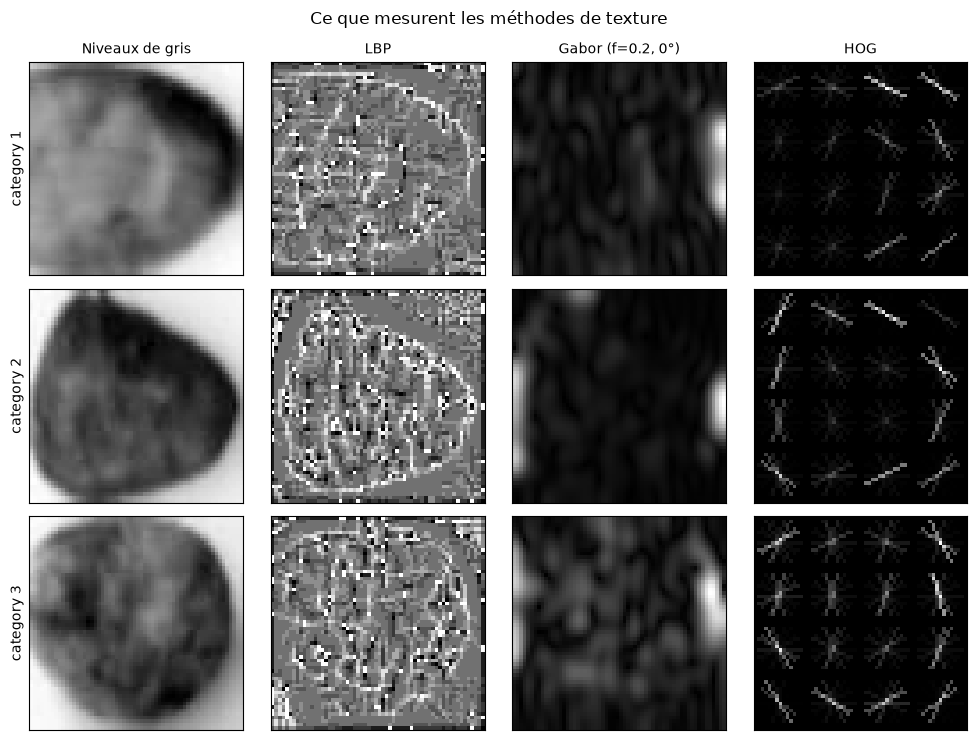

In [6]:
#Visualiser ce que « voit » chaque méthode

rng = np.random.default_rng(42)
exemples = [rng.choice(np.where(y == c)[0]) for c in range(3)]
classes = ["category 1", "category 2", "category 3"]

fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for ligne, idx in enumerate(exemples):
    g = gris[idx]
    lbp_img = local_binary_pattern(g, P=8, R=1, method="uniform")
    noyau = gabor_kernel(0.2, theta=0)
    gabor_img = np.sqrt(cv2.filter2D(g.astype(np.float32) / 255, -1, np.real(noyau).astype(np.float32)) ** 2 +
                        cv2.filter2D(g.astype(np.float32) / 255, -1, np.imag(noyau).astype(np.float32)) ** 2)
    _, hog_img = hog(g, orientations=9, pixels_per_cell=(15, 15), cells_per_block=(2, 2), visualize=True)

    for col, (image, titre) in enumerate([(g, "Niveaux de gris"), (lbp_img, "LBP"),
                                          (gabor_img, "Gabor (f=0.2, 0°)"), (hog_img, "HOG")]):
        axes[ligne, col].imshow(image, cmap="gray")
        axes[ligne, col].set_xticks([]); axes[ligne, col].set_yticks([])
        if ligne == 0:
            axes[ligne, col].set_title(titre, fontsize=10)
    axes[ligne, 0].set_ylabel(classes[ligne])

plt.suptitle("Ce que mesurent les méthodes de texture")
plt.tight_layout()
plt.savefig("../results/figures/04_visualisation_texture.png", dpi=150)
plt.show()

In [7]:
#Calcul pour toutes les images


textures = {"glcm": texture_glcm, "lbp": texture_lbp, "gabor": texture_gabor, "hog": texture_hog}

for nom, fonction in textures.items():
    df_tex = pd.DataFrame([fonction(g) for g in gris])
    df_tex.insert(0, "fichier", df["fichier"])
    df_tex.insert(1, "classe", df["classe"])
    df_tex.to_csv(f"../results/features/caracteristiques_{nom}.csv.gz", index=False)
    print(f"{nom.upper():6s} : {df_tex.shape[1] - 2} caractéristiques | valeurs manquantes : {df_tex.isna().sum().sum()}")

GLCM   : 8 caractéristiques | valeurs manquantes : 0
LBP    : 10 caractéristiques | valeurs manquantes : 0
GABOR  : 24 caractéristiques | valeurs manquantes : 0
HOG    : 324 caractéristiques | valeurs manquantes : 0


**Observations sur la texture :**
- **LBP** distingue clairement la surface irrégulière de la fève (motifs variés) du fond uniforme ; un léger bruit de compression JPEG apparaît dans le fond.
- **Gabor** réagit fortement aux contours de la fève (bords perpendiculaires à l'orientation du filtre) : ses caractéristiques mélangent donc texture de surface et forme.
- **HOG**, avec seulement 4 × 4 cellules sur une image de 60 × 60 pixels, décrit essentiellement la silhouette de la fève plutôt que sa surface.
- Les textures étant calculées sur l'image entière, la forme de la fève influence une partie des caractéristiques. Comme la forme dépend peu de la catégorie, on s'attend à ce que HOG soit peu discriminant malgré son grand nombre de caractéristiques (324).

In [8]:
#Construire les ensembles de caractéristiques

# Relecture des matrices enregistrées
F = {nom: pd.read_csv(f"../results/features/caracteristiques_{nom}.csv.gz").drop(columns=["fichier", "classe"])
     for nom in ["couleur", "glcm", "lbp", "gabor", "hog"]}

def couleur_espace(espace):
    return F["couleur"][[c for c in F["couleur"].columns if c.startswith(espace + "_")]]

texture = pd.concat([F["glcm"], F["lbp"], F["gabor"], F["hog"]], axis=1)

ensembles = {
    "Couleur RGB": couleur_espace("RGB"),
    "Couleur HSV": couleur_espace("HSV"),
    "Couleur LAB": couleur_espace("LAB"),
    "Texture (GLCM+LBP+Gabor+HOG)": texture,
    "Texture sans HOG": pd.concat([F["glcm"], F["lbp"], F["gabor"]], axis=1),
    "Couleur LAB + texture sans HOG": pd.concat([couleur_espace("LAB"), F["glcm"], F["lbp"], F["gabor"]], axis=1),
}
for nom, matrice in ensembles.items():
    print(f"{nom:35s} : {matrice.shape[1]} caractéristiques")

Couleur RGB                         : 45 caractéristiques
Couleur HSV                         : 45 caractéristiques
Couleur LAB                         : 45 caractéristiques
Texture (GLCM+LBP+Gabor+HOG)        : 366 caractéristiques
Texture sans HOG                    : 42 caractéristiques
Couleur LAB + texture sans HOG      : 87 caractéristiques


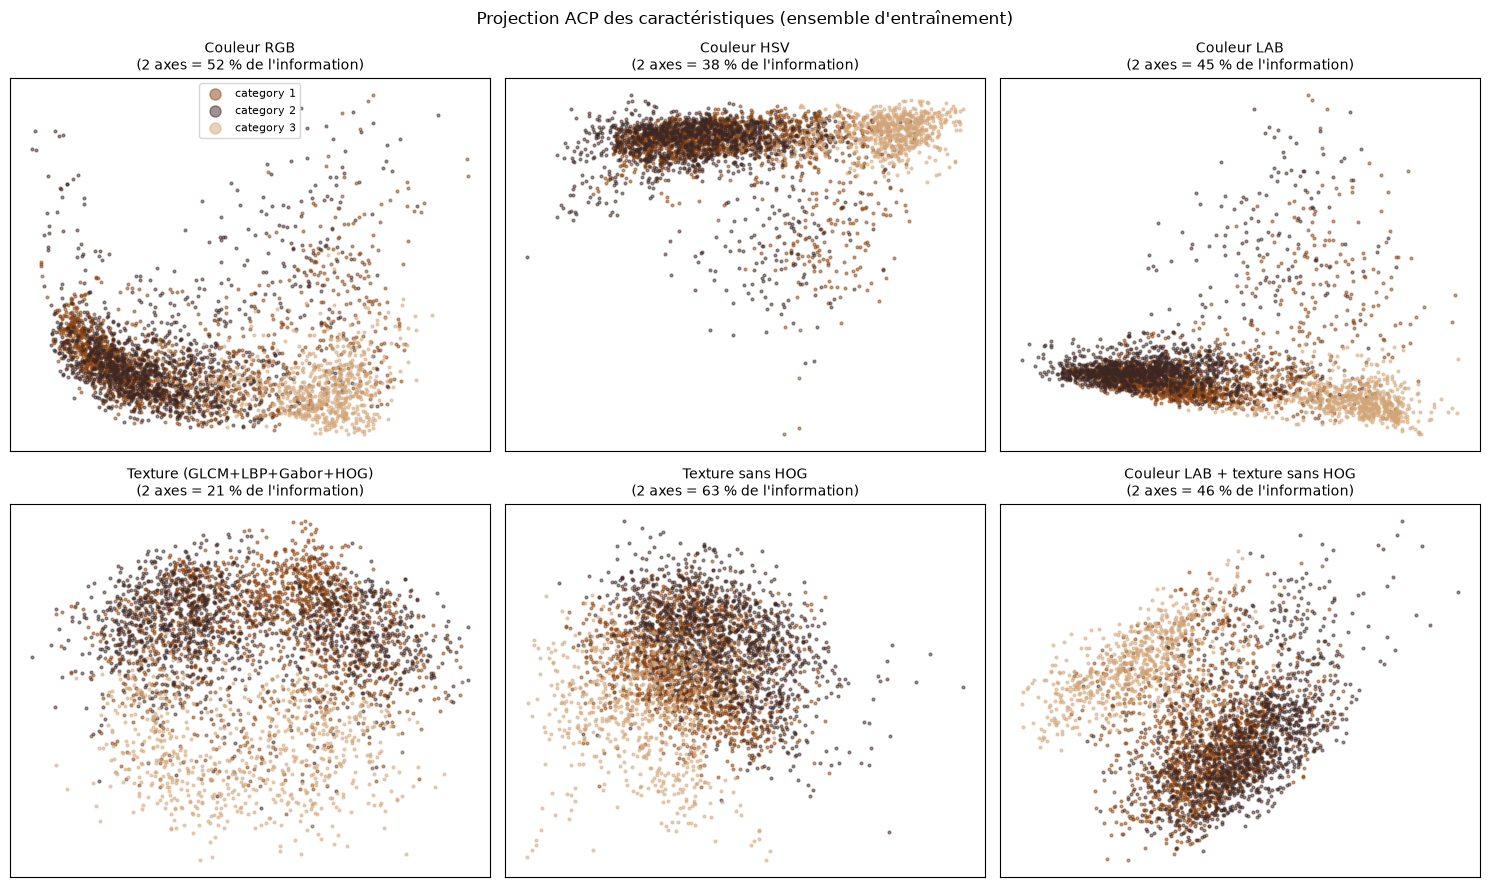

In [9]:
#ACP de chaque ensemble

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

idx_train = np.where(df["partition"] == "train")[0]
y_tr = y[idx_train]
couleurs_classes = ["#8B4513", "#3E2723", "#D2A679"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (nom, matrice) in zip(axes.ravel(), ensembles.items()):
    Z = StandardScaler().fit_transform(matrice.values[idx_train])
    acp = PCA(n_components=2, random_state=42)
    Z2 = acp.fit_transform(Z)
    for c in range(3):
        ax.scatter(Z2[y_tr == c, 0], Z2[y_tr == c, 1], s=4, alpha=0.5,
                   color=couleurs_classes[c], label=classes[c])
    variance = acp.explained_variance_ratio_.sum() * 100
    ax.set_title(f"{nom}\n(2 axes = {variance:.0f} % de l'information)", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend(markerscale=4, fontsize=8)
plt.suptitle("Projection ACP des caractéristiques (ensemble d'entraînement)")
plt.tight_layout()
plt.savefig("../results/figures/04_acp_ensembles.png", dpi=150)
plt.show()

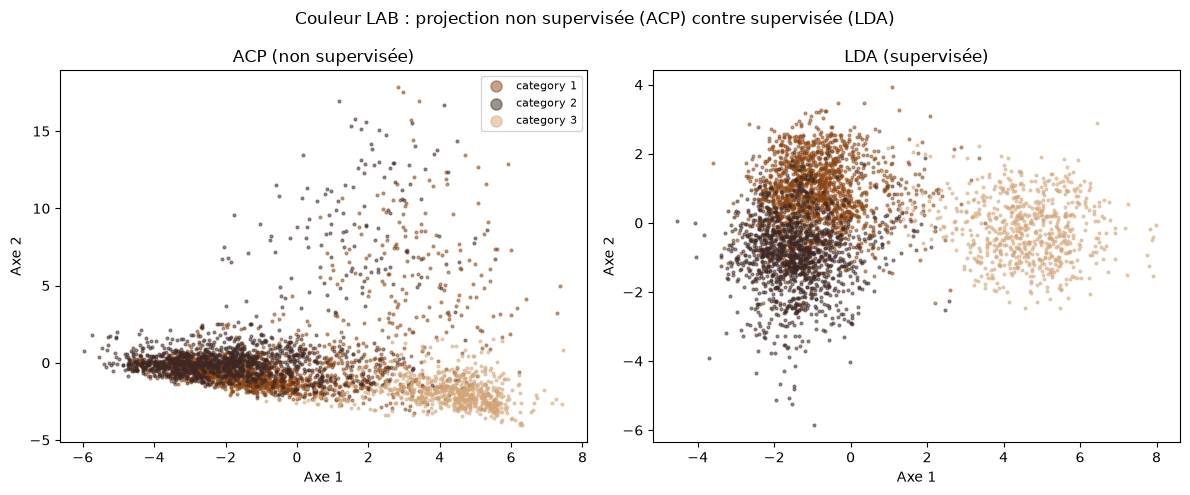

In [10]:
#ACP contre LDA sur la couleur LAB

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

Z = StandardScaler().fit_transform(ensembles["Couleur LAB"].values[idx_train])
projections = {
    "ACP (non supervisée)": PCA(n_components=2, random_state=42).fit_transform(Z),
    "LDA (supervisée)": LinearDiscriminantAnalysis(n_components=2).fit_transform(Z, y_tr),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nom, Z2) in zip(axes, projections.items()):
    for c in range(3):
        ax.scatter(Z2[y_tr == c, 0], Z2[y_tr == c, 1], s=4, alpha=0.5,
                   color=couleurs_classes[c], label=classes[c])
    ax.set_title(nom)
    ax.set_xlabel("Axe 1"); ax.set_ylabel("Axe 2")
axes[0].legend(markerscale=4, fontsize=8)
plt.suptitle("Couleur LAB : projection non supervisée (ACP) contre supervisée (LDA)")
plt.tight_layout()
plt.savefig("../results/figures/04_acp_vs_lda_LAB.png", dpi=150)
plt.show()

**Projections ACP :**
- La **Category 3** se sépare nettement dans tous les ensembles de caractéristiques, y compris avec la **texture seule** : la texture apporte donc une information propre, complémentaire de la couleur.
- Les **Categories 1 et 2** restent superposées dans les projections ACP. Cela ne signifie pas qu'elles sont inséparables : l'ACP, non supervisée, retient les directions de plus grande variance (luminosité, Category 3), alors que la différence entre les Categories 1 et 2 est plus subtile (nuance bleu-violet, étape 3).
- Une **LDA**, supervisée, fait apparaître sur son deuxième axe une séparation partielle des Categories 1 et 2 : la paire 1 / 2 sera la principale difficulté de la classification.
- Avec **HOG**, deux axes ne résument que 21 % de l'information : ses 324 caractéristiques décrivent surtout la forme et ajoutent de la dispersion. Son utilité sera vérifiée à l'étape 5.

## Conclusion de l'étape 4

- Chaque image est décrite par **591 caractéristiques** : 225 de couleur (15 mesures × 3 canaux × 5 espaces, calculées sur la fève avec un masque érodé d'un pixel) et 366 de texture (GLCM 8, LBP 10, Gabor 24, HOG 324).
- Les matrices sont enregistrées dans `results/features/` (une par famille), avec le nom du fichier et la classe, pour l'étape 5.
- La couleur et la texture séparent toutes deux la Category 3 ; la distinction entre les Categories 1 et 2 repose sur des différences plus fines, visibles seulement avec une méthode supervisée.
- Hypothèses à vérifier à l'étape 5 : les espaces HSV et LAB devraient surpasser RGB ; la combinaison couleur + texture devrait améliorer les résultats ; HOG devrait apporter peu.